# 20 - Petrophys for LLM agents (MCP)

**Part B - Petrophys Curriculum**

LLM applications such as Claude Desktop, Claude Code, Cursor and VS Code can call
tools through the **Model Context Protocol (MCP)**. Petrophys ships an MCP server, so a
model can load wells, run the interpretation, read the trace, summarize zones, plot
logs and export results - using exactly the validated workflow you have learned in
this course, never a re-implementation of the physics.

## Learning goals

- Start the Petrophys MCP server and see the tools a model is offered.
- Follow a complete agent session: load, interpret, explain, summarize, plot, export.
- See how the server keeps the model honest: validated settings, actionable errors,
  skip reasons and data-quality warnings in every answer.
- Connect a real MCP client to your own well folders.

## Why this matters

A language model is good at planning an analysis and explaining it, but it must not
invent petrophysics. With MCP the model *calls* Petrophys: every number it reports comes
from the same traced workflow as `pp.interpret`, every skipped step has a stated
reason, and every setting it passes is validated before anything runs. The server also
limits file access to folders you choose.

### Prerequisites

The MCP extra needs Python 3.10+: `pip install "petrophys[mcp]"`. Real clients start
the server as a separate process (`petrophys-mcp`); in this notebook we connect to it
in-process with the MCP Python client, which sends exactly the same requests.

## 1 - Start the server and list its tools

In [1]:
import json
from base64 import b64decode
from pathlib import Path

from IPython.display import Image, display
from mcp import Client

import petrophys as pp
from petrophys.mcp import create_server

print("petrophys", pp.__version__)

# The server keeps loaded wells and results; clients can connect and disconnect.
server = create_server(roots=["."])          # the folders the model may read and write

async with Client(server) as client:
    tools = (await client.list_tools()).tools
for tool in tools:
    print(f"{tool.name:26s} {tool.description.splitlines()[0]}")

petrophys 3.0.0


list_sample_wells          List the bundled sample wells by collection, with what each is good for.
interpretation_settings    Look up interpret_well settings (name, default, unit, accepted values).
load_well                  Load a well file and summarize it.
load_sample_well           Load a bundled sample well; returns the same summary as load_well.
list_loaded                List the wells and interpretation runs held in this session, with their ids.
describe_well              Summarize a loaded well again (same content as load_well) without reloading it.
check_data_quality         Data-quality report with a recommended fix for every problem.
curve_statistics           Statistics of curves over a depth window: valid count, min, P10, median, mean, P90, max.
curve_values               Curve values versus depth, decimated, for inspecting a short interval.
interpret_well             Run the full interpretation (petrophys.interpret) on a well and summarize it.
interpret_wells           

Each tool comes with a JSON schema whose parameters are described for the model. Below
are the parameters of `load_well` with their descriptions (the full schema also carries
types and defaults). A small helper calls a tool and returns its JSON result:

In [2]:
async def call_raw(tool, **arguments):
    async with Client(server) as client:
        return await client.call_tool(tool, arguments)


async def call(tool, **arguments):
    result = await call_raw(tool, **arguments)
    if result.is_error:
        raise RuntimeError(result.content[0].text)
    return result.structured_content


def show(data, limit=1500):
    text = json.dumps(data, indent=2)
    print(text if len(text) <= limit else text[:limit] + "\n...")


load_schema = next(tool for tool in tools if tool.name == "load_well").input_schema
for name, spec in load_schema["properties"].items():
    print(f"{name:12s} {spec.get('description', '')}")
print("required:", load_schema.get("required", []))

path         LAS, DLIS, CSV or TSV file inside the allowed folders; relative paths start in the server's folder (e.g. 'my_well.las').
depth_unit   Depth unit; required for CSV/TSV files.
formations   Formation tops/intervals file (CSV/Excel) to attach; enables per-formation summaries and tops on plots.
lithology    Lithology intervals file (top, bottom, lithology) to attach.
well_id      Id to store the well under; defaults to the well name.
required: ['path']


## 2 - What the model knows about settings

`interpretation_settings` lists every setting with its unit, default and accepted
values - the machine-readable form of `DynamicWorkflowConfig`.

In [3]:
settings = await call("interpretation_settings")
by_name = {item["name"]: item for item in settings["settings"]}
show({name: by_name[name] for name in ["rw", "bht_f", "sw_model"]})

{
  "rw": {
    "name": "rw",
    "default": "header RW (at RWT; 75 degF assumed when RWT is missing)",
    "description": "Formation water resistivity Rw, ohm.m, at rw_meas_temp_f"
  },
  "bht_f": {
    "name": "bht_f",
    "default": "header BHT (converted to degF)",
    "description": "Bottom-hole temperature, degF"
  },
  "sw_model": {
    "name": "sw_model",
    "default": "auto",
    "description": "\"auto\" (routed per sample by clay content) or one of \"archie\", \"simandoux\", \"indonesia\", \"dual_water\", \"waxman_smits\", \"north_sea\", \"nigeria_schlumberger\"",
    "choices": [
      "auto",
      "archie",
      "north_sea",
      "nigeria_schlumberger",
      "simandoux",
      "indonesia",
      "dual_water",
      "waxman_smits"
    ]
  }
}


## 3 - Load a well

In [4]:
well = await call("load_sample_well", name="30_6-5", with_geology=True)
print(well["well_id"], "|", well["name"], "|", well["header"]["field"])
print(f"{well['top']:.0f}-{well['bottom']:.0f} {well['depth_unit']}, {len(well['curves'])} curves")
print("header:", well["header_parameters"])
for note in well["header_notes"]:
    print("note:", note[:110])
name = well["formation_columns"].index(next(col for col in well["formation_columns"] if "name" in col or col == "formation"))
print("formations:", [row[name] for row in well["formations"][:6]], "...")
print("curves:", [row[0] for row in well["curves"]][:15])

30_6-5 | 30/6-5 | OSEBERG ØST
177-3556 m, 20 curves
header: {'CLFL': '20366 mg/l', 'RW': '0.7 ohmm', 'RMF': '0.08 ohmm', 'BHT': '126 degC (= 258.8 degF)'}
note: Header RW = 0.7 ohmm has NO measurement temperature (no RWT). Without an rw setting interpret_well uses it at 
note: Header RW (0.7) is higher than RMF (0.08). Formation water is normally saltier (lower resistivity) than the mu
note: BHT is 126 degC = 258.8 degF. Settings such as bht_f and rw_meas_temp_f are in degF.
formations: ['NORDLAND GP.', 'Utsira Fm.', 'HORDALAND GP.', 'ROGALAND GP.', 'Balder Fm.', 'Sele Fm.'] ...
curves: ['LITHOLOGY_GEOLINK', 'CALI', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DTE', 'RDEP', 'SP', 'RSHA', 'RMED', 'BS', 'PHIC']


## 4 - Interpret

The model passes only what the logs cannot provide. Formation water resistivity is the
classic example: the server's instructions tell the model to ask the user for `rw`
rather than assume a value. Here we supply the study value of 0.07 ohm.m, measured at 230 degF, and ask for
key results over the Brent Group (2841-2958 m).

In [5]:
run = await call(
    "interpret_well",
    well_id="30_6-5",
    settings={"rw": 0.07, "rw_meas_temp_f": 230},   # Rw (ohm.m) at 230 degF
    summary_top=2841,
    summary_bottom=2958,
)
show({key: run[key] for key in ["interpretation_id", "status", "resolved", "settings_used", "skipped_steps", "net_thickness"]})
for name, stats in run["key_results"].items():
    print(f"{name:5s} median {stats['median']:.3f} {stats['unit']}")

{
  "interpretation_id": "30_6-5/run-1",
  "status": "interpreted",
  "resolved": {
    "matrix_type": "sandstone",
    "lithology_domain": "clastic"
  },
  "settings_used": {
    "rmf_salinity_ppm": 20366.0,
    "rw": 0.07,
    "rw_meas_temp_f": 230,
    "matrix_type": "sandstone",
    "formation_tops": "attached"
  },
  "skipped_steps": {
    "spectral_gamma": "not part of interpret_well; use the spectral_gamma tool",
    "elemental_spectroscopy": "not part of interpret_well",
    "hc_correction": "apply_hc_correction=False (hydrocarbon correction is opt-in)"
  },
  "net_thickness": {
    "gross": 117.04,
    "net_rock": 88.36,
    "net_reservoir": 87.3,
    "net_pay": 37.78,
    "depth_unit": "m"
  }
}
VCL   median 0.075 v/v
PHIT  median 0.203 v/v
PHIE  median 0.201 v/v
SW    median 0.629 v/v
PERM  median 760.180 mD


Every skipped step carries its reason, and the settings actually used - including the
matrix and lithology resolved from the data - are part of the answer.

## 5 - When the model gets it wrong

Invalid requests fail *before* anything runs, with a message the model can act on:

In [6]:
for tool, arguments in [
    ("interpret_well", {"well_id": "30_6-5", "settings": {"hc_type": "gass"}}),
    ("load_well", {"path": "/etc/passwd"}),
    ("explain_step", {"interpretation_id": "30_6-5/run-9", "step": "rw"}),
]:
    result = await call_raw(tool, **arguments)
    message = result.content[0].text.replace(str(Path.cwd()), ".")  # hide this machine's path
    print(f"{tool}: {message}\n")

interpret_well: Error executing tool interpret_well: Invalid DynamicWorkflowConfig:
  - hc_type='gass' is not valid; use one of: oil, gas (did you mean 'gas'?)

load_well: Error executing tool load_well: '/etc/passwd' is outside the folders this server may access ('petrophys-tutorial-9nz4oumj'). Use a path inside them (relative paths start in 'petrophys-tutorial-9nz4oumj'); the user can add folders with --root <folder> or PETROPHYS_MCP_ROOTS.

explain_step: Error executing tool explain_step: Unknown interpretation id '30_6-5/run-9'. Known interpretation ids: 30_6-5/run-1. Did you mean '30_6-5/run-1'?



## 6 - Explain a result

`explain_step` returns the full trace record of one step - the method, the inputs, the
parameters and every decision - so the model can justify a number:

In [7]:
rw_step = await call("explain_step", interpretation_id=run["interpretation_id"], step="rw")
show({key: rw_step[key] for key in ["method", "parameters", "decisions"]})

{
  "method": "user_provided_temperature_profile_corrected",
  "parameters": {
    "rw_at_measured_temp": 0.07,
    "measured_temp_f": 230,
    "source_priority": "config.rw",
    "rw_min": 0.06241,
    "rw_max": 0.1967,
    "formation_temp_min_f": 77.48,
    "formation_temp_max_f": 258.8
  },
  "decisions": [
    "Rw directly corrected from 0.0700 ohm.m @ 230F with Arps along the temperature profile"
  ]
}


## 7 - Summarize zones

In [8]:
brent = await call("summarize_zones", interpretation_id=run["interpretation_id"], top=2841, bottom=2958)
zone = brent["zones"][0]
print(f"Brent: gross {zone['gross_thickness']:.1f} m, net pay {zone['net_pay']:.1f} m, "
      f"avg PHIE {zone['avg_phie']:.3f}, avg Sw {zone['avg_sw']:.3f}")

by_formation = await call("summarize_zones", interpretation_id=run["interpretation_id"])
for row in by_formation["zones"]:
    if row["Net Pay (m)"]:
        depths = f"{row['Top']:.0f}-{row['Bottom']:.0f} m"
        print(f"{row['Formation']:15s} {depths:>12s}   net pay {row['Net Pay (m)']:6.1f} m")

Brent: gross 117.0 m, net pay 37.8 m, avg PHIE 0.213, avg Sw 0.376
NORDLAND GP.       181-726 m   net pay  447.4 m
Utsira Fm.         726-879 m   net pay   35.7 m
HORDALAND GP.     879-1908 m   net pay  103.3 m
ROGALAND GP.     1908-2203 m   net pay   28.0 m
Balder Fm.       1908-2023 m   net pay   27.6 m
Lista Fm.        2123-2203 m   net pay    0.5 m
SHETLAND GP.     2203-2408 m   net pay    2.4 m
VIKING GP.       2452-2841 m   net pay    0.8 m
Heather Fm.      2593-2841 m   net pay    0.8 m
BAAT GP.         2841-2958 m   net pay   37.8 m
Ness Fm.         2841-2865 m   net pay    6.7 m
Etive Fm.        2865-2958 m   net pay   31.1 m
DUNLIN GP.       2958-3223 m   net pay    5.3 m
Cook Fm.         3071-3123 m   net pay    5.3 m
Statfjord Fm.    3223-3556 m   net pay    3.7 m


Read the per-formation list with care - a model has to as well:

- The bundled 30/6-5 tops mix **groups** (`GP.`) with the **formations** inside them,
  so rows overlap: `BAAT GP.` (the Brent Group) contains the Ness and Etive
  formations. Never add these rows up.
- If shallow groups such as Nordland or Hordaland (above roughly 1900 m) show net pay,
  that is not a reservoir: unconsolidated overburden sediments can pass the default
  porosity and saturation cutoffs. Exclude them by choosing the reservoir interval, as
  the Brent window above does - and ask the model to do the same.

## 8 - Plot

image/png


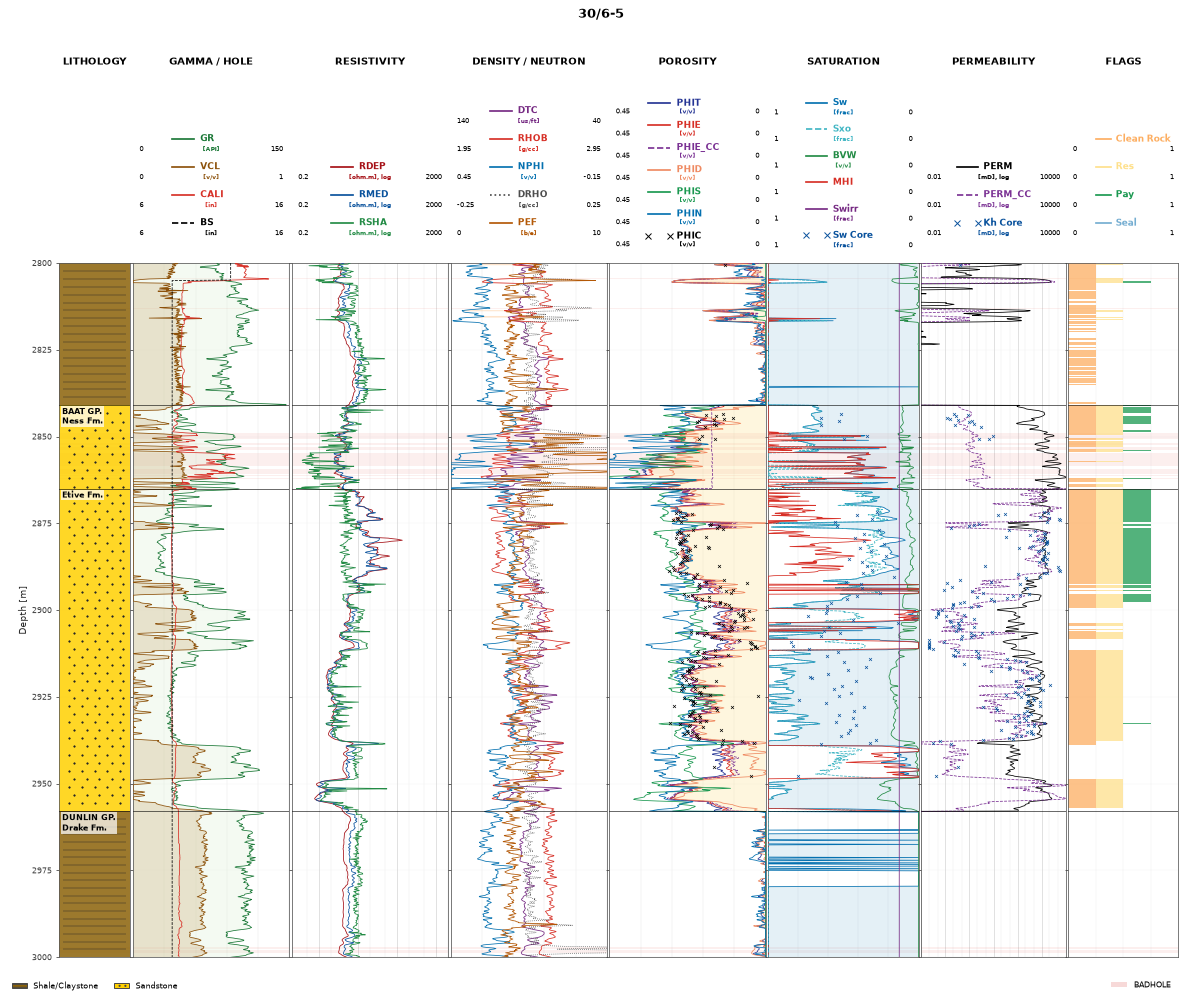

In [9]:
result = await call_raw(
    "plot_well", target_id=run["interpretation_id"], top=2800, bottom=3000, dpi=70
)
image = result.content[0]
print(image.mime_type)
display(Image(data=b64decode(image.data)))

## 9 - Export

`export_results` writes inside the allowed folders; a relative path starts at the first
root (here the notebook's working folder), and an existing file is overwritten.

In [10]:
exported = await call("export_results", interpretation_id=run["interpretation_id"], path="exports/30_6-5.las")
print(exported["format"], exported["bytes"], "bytes")

las 15416542 bytes


## 10 - Connect a real client

Install the extra, check it, and let `petrophys-mcp config` print the exact setup for your
client (Claude Code, Claude Desktop, Cursor, VS Code or Codex):

```bash
pip install "petrophys[mcp]"
petrophys-mcp check --root /path/to/wells
petrophys-mcp config claude-code --root /path/to/wells
```

For a model that is not on your machine - a team server, a container, or a hosted model
such as OpenAI's - serve over HTTP with a token (`docker compose up` does the same in a
container):

```bash
petrophys-mcp serve --http --root /path/to/wells --token auto
petrophys-mcp config openai --url https://<your-host>/mcp --token <TOKEN>
```

`examples/mcp_openai_agent.py` connects an OpenAI model to a local server without a
public URL. The [LLM agents (MCP) guide](https://petrophys.netlify.app/mcp) covers every
option.
Then ask, for example: *"Load my_well.las, interpret it with Rw = 0.05 ohm.m at 75 degF,
and tell me the net pay in each formation - list any warnings."*

## Pitfalls

- **Rw needs its temperature.** Pass `rw` together with `rw_meas_temp_f` in `settings`;
  without it the library assumes 75 degF. Tell the model both values, or let it ask.
- **Mixed group/formation tops overlap.** Summaries per zone are not additive when the
  tops file mixes levels; `summarize_zones(rank="formation")` keeps one level.
- **Whole-well totals can include the overburden.** Ask for the reservoir window
  (`summary_top`/`summary_bottom`, or `summarize_zones` with `top`/`bottom`).
- **File access is sandboxed.** Paths outside the `--root` folders are refused, and
  exports land inside them.

## Key takeaways

- The MCP server gives a model the Petrophys workflow, not a copy of it: results,
  traces and warnings are the ones `pp.interpret` produces.
- Settings are validated and errors are actionable, so a model can correct itself.
- File access is limited to the folders passed with `--root`.

## Try it yourself

> **Exercise 1.** Call `curve_statistics` with `target_id=run["interpretation_id"]`,
> `curves=["PHIE", "SW", "VCL"]` and the Brent window. Do the medians agree with
> `run["key_results"]`?
>
> **Exercise 2.** Run `interpret_well` again with `settings={"rw": 0.07}` only, then use
> `explain_step` on the new run's `rw` step. Which temperature was assumed, and how does
> the Brent average Sw from `summarize_zones` change?

## What's next

Next, **21_custom_workflows.ipynb** turns your interpretation into a reusable, shareable workflow. Apply the course end to end in the case studies (for example
`cs1_full_formation_evaluation_30_6-5.ipynb`), or bring your own well with
`own_data.ipynb`.